# Holdout Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for evaluating the explicitly selected Meta and Primary configurations; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `sentiment_asynchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `holdout` — Use the fixed holdout evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- Set `RESULT_DIRECTORY` to the folder for this run. Use a separate folder to keep the results of another run.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-07-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `horizon_bars=780`, `horizontal_multipliers=[5, 4]`, `max_positions_per_side=10`, `step_size=0.10`, `half_life_minutes=390.0`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set holding horizon, the total position limit per direction in the single book, sizing, initial capital, and trading costs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[3]

STRATEGY = "market_asynchronous"
PARTITION = "holdout"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"
RESULT_DIRECTORY = PROJECT_ROOT / "data/backtesting" / STRATEGY / "tp5_sl4" / PARTITION

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-07-01", tz="UTC")

settings = PortfolioSettings(
    horizon_bars=780,
    horizontal_multipliers=[5, 4],
    max_positions_per_side=10, step_size=0.10, half_life_minutes=390.0,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="market", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Holdout Predictions

- **Purpose:** Validate saved holdout predictions without refitting, tuning, or selecting a winner on holdout.
- **Input:** Family-tagged holdout predictions, fixed event/partition keys, and canonical primary predictions.
- **Output:** Validated predictions in memory; missing/duplicate events, mixed partitions, or inconsistent primary predictions are rejected.

In [3]:
validation_settings = None
splits = None
predictions = holdout_predictions(inputs)

## Bet Sizing

- **Purpose:** Prepare signed signals with split-training-only price calibration; rank eligible candidates by meta probability and session-time decay.
- **Input:** Frozen-model out-of-sample predictions and training-only calibration data.
- **Output:** Events and aligned calibration tables; the execution engine uses the latest signal per symbol and equal capital slots.


In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared completed dollar-bar stream.
- **Execution:** Observe completed bars, decide causally, and fill only on a later own-symbol bar; enforce fixed entry limits, reduction-before-increase execution, and final-bar liquidation.
- **Selection:** Select new symbols initially, on event termination, or after completed liquidation. Other registrations update the bounded priority queue; limit violations cancel without replacement.
- **Signals:** Each new event supersedes the symbol's previous signal and restarts its own barrier clock. A rejected or directionless latest signal closes the position; superseded signals cannot return.
- **Allocation:** For `n` selected symbols on a side, target `side * min(0.5 / n, 1 / K)` of current AUM. With `K=10`, each symbol is capped at 10%; each side uses at most 50%. Unused capacity stays in cash. Resize on membership changes, not probability changes alone.
- **Recording:** The simulation retains minute-last, fills, session-close and terminal/boundary observations.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing dollar bars


Dollar bars:   0%|          | 0/24944105 [00:00<?, ?bar/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** One selected-model statistics table and one cumulative-return graph; save `statistics.parquet` and `settings.json` under `RESULT_DIRECTORY`. Account curves, detailed trades, and intermediate predictions remain in memory; see the [storage decision](../../../../docs/decisions.md#12-database).
- **Display:** For the explicitly selected model family, show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; Primary reports precision/recall/F1 for both -1 and +1, Meta for class 1, and both report accuracy, weighted balanced accuracy immediately after F1 for class 1, positive log loss, PR-AUC, and ROC-AUC using the shared modeling calculations; no classification graphs are added; recompute statistics before rerunning display to obtain the new metrics; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Model-family headings are omitted; graph titles show only strategy and partition. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

holdout
section                  metric                          unit                                 
general_characteristics  start                           timestamp   2026-01-01T00:00:00+00:00
                         end                             timestamp   2026-06-30T20:00:00+00:00
                         average_aum                     USD                104195.68550061555
                         leverage                        ratio              0.5770735293871965
                         maximum_dollar_position_size    USD                108235.37715424129
                         ratio_of_longs                  ratio              0.5477424130273871
                         frequency_of_bets               count/year         2728.7709677419352
                         average_holding_period          days               0.9355512216388409
                         annualized_turnover             ratio               491.2644968704985
                         correlation_to_underlying       ratio           -0.023050907616500606
performance              pnl                             USD                5789.0049961309705
                         annualized_rate_of_return       ratio             0.12038005838310539
                         pnl_from_long_positions         USD                3803.6374999852405
                         pnl_from_short_positions        USD                1985.3674961454356
                         hit_ratio                       ratio             0.44929681717246484
                         average_return_from_hits        ratio            0.001661581858779418
                         average_return_from_misses      ratio          -0.0012753914495888155
runs                     hhi_positive_returns            ratio           0.0013674033902110333
                         hhi_negative_returns            ratio           0.0010039312844447932
                         hhi_time_between_bets           ratio           0.0025791132045183017
                         percentile_drawdown             ratio            0.004265101156902734
                         percentile_time_under_water     years            0.004029766276047608
implementation_shortfall broker_fees_per_turnover        ratio           9.999999571571419e-05
                         average_slippage_per_turnover   ratio          0.00010000000000000015
                         dollar_performance_per_turnover ratio           0.0002284286355645355
                         return_on_execution_costs       ratio              1.1421432022890163
efficiency               sharpe_ratio                    ratio            0.037620277843879946
                         annualized_sharpe_ratio         ratio              0.7189804988104872
                         probabilistic_sharpe_ratio      ratio             0.42217808725645267
classification_scores    primary_accuracy                score               0.596950059501702
                         primary_precision_-1            score              0.5821569087310828
                         primary_recall_-1               score              0.5777314057420007
                         primary_f1_-1                   score              0.5799357145802695
                         primary_precision_1             score              0.6104917981847979
                         primary_recall_1                score              0.6148028803543878
                         primary_f1_1                    score              0.6126397552043886
                         primary_balanced_accuracy       score              0.5962671430481953
                         primary_log_loss                score              0.6514563857103269
                         primary_pr_auc                  score              0.6549813114778297
                         primary_roc_auc                 score              0.6533047154123691
                         meta_accuracy                   score              0.5740657192517835
  

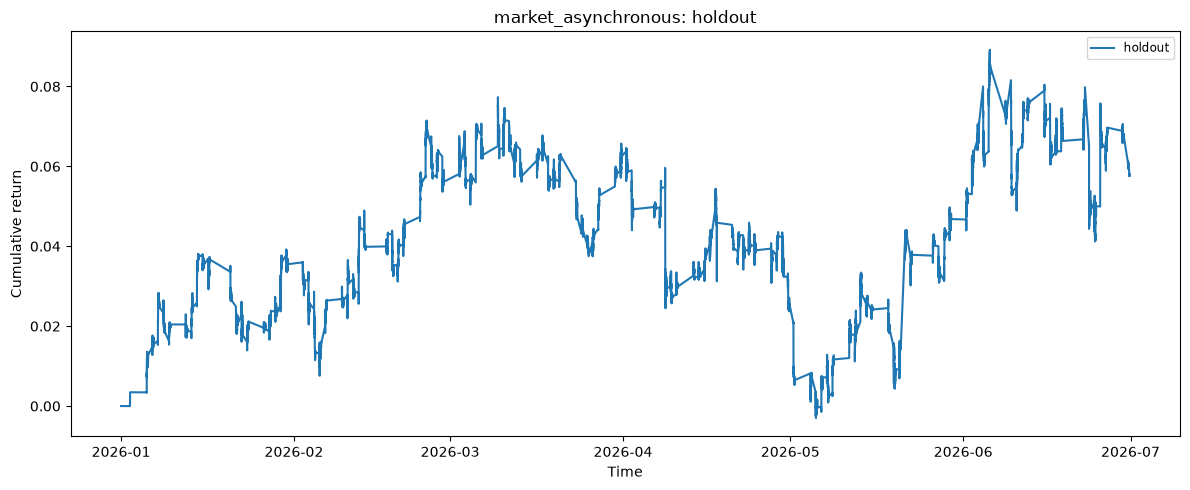

In [7]:
for family in statistics["model_family"].drop_duplicates():
    family_statistics = statistics.loc[statistics["model_family"].eq(family)].set_index(
        ["section", "metric", "unit"],
    )
    display_values = family_statistics.drop(columns="model_family")
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(display_values)

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
    result_directory=RESULT_DIRECTORY,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/market_asynchronous/tp5_sl4/holdout
